In [1]:
source('../../../R/preamble.R')

dark_red = '#F24A14'

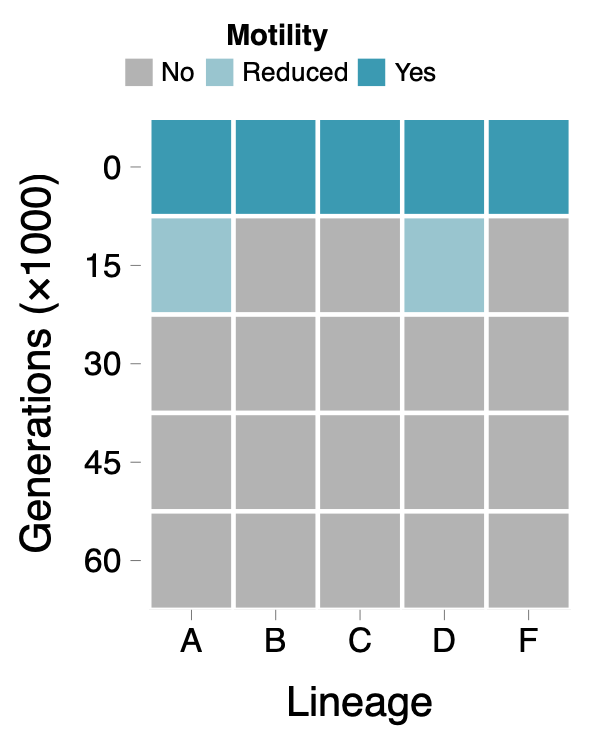

In [2]:
pure = c('A','B','C','D','F')
labels = c('yes'='Yes', 'no'='No', 'reduced'='Reduced')
palette = c('Yes'=pal[1], 'Reduced'='#99c5cf', 'No'='grey70')
#palette = c('Yes'=pal[1], 'Reduced'='#99c5cf', 'No'='#806962')

small_legend = theme(
    legend.margin = margin(0,-5,-5,-5),
    legend.key.spacing = unit(0.3, 'mm'),
    legend.key.size = unit(3.2,'mm'), 
    legend.text = element_text(size=6.3),
    legend.justification = 'left',
    legend.title = element_text(size=7, face='bold')
)

small_titles = theme(axis.title = element_text(size=10))
small_text = theme(axis.text = element_text(size=8))

motility_vert_top =
read.tsv('../../../datasets/adhesion/motility_summary/microscopy_summary.csv', check.names = F) %>% 
    pivot_longer(-pop, names_to = 'gen', values_to = 'motility') %>%
    mutate(
        gen = 2.5*as.numeric(gen),
        motile = labels[motility]
    ) %>% 
    filter(pop %in% pure) %>% 

ggplot() + aes((pop), fct_rev(factor(gen)), fill=motile) + 

    coord_cartesian(ylim = c(1, 5)) +
    scale_y_discrete(expand = expansion(add = 0.5)) +

    geom_tile(
        col = w, lwd = 0.5
    ) +

    #theme_minimal() +
    theme(
        axis.line = eb,
        panel.grid=eb, 
        #axis.text.x = element_text(face='plain', size=10), 
        #axis.title.x = eb #element_text(hjust=0.4)
    ) +

    #theme(legend.position = 'top') +
    guides(fill = guide_legend(ncol = 3, position = 'top', title.position='top', title.hjust=0.5)) +

    scale_fill_manual(values = palette) +
    small_text + small_titles + small_legend +
    
    labs(y = 'Generations (×1000)', x = 'Lineage', fill = 'Motility')

size(2.5, 2)
motility_vert_top
psave('Plots/motility_tile_vert_top')